# 03 - Exploratory data analysis (EDA)

**Goal:** understand the data before modelling, and collect the evidence you will use to **justify every project decision**
(onset windows, thresholds, which variables matter).

Each section answers one question an instructor could ask. Under each chart, write down what you see in your own words.

**Needs:** the processed tables from `01_cleaning` and `02_merging`, and for sections 7-10 the output of `create_labels.py` and `build_features.py`
(run `python ML\Src\processing\run_processing.py` once).

In [14]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Find ML/Src/processing from wherever the notebook is opened (ML/Notebooks or the project root)
here = Path.cwd().resolve()
candidates = [here, here.parent, here / "ML", here.parent / "ML", *here.parents]
PROC_SRC = next((c / "Src" / "processing" for c in candidates
                 if (c / "Src" / "processing" / "pipeline_common.py").exists()), None)
assert PROC_SRC is not None, "Could not find Src/processing - open this notebook from the ML/Notebooks folder."
sys.path.insert(0, str(PROC_SRC))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pipeline_common import (RAW_DIR, PROC_DIR, DATA_DIR, REGIONS, REGION_NAMES,
                             read_region_files, read_static_file, load_table, save_table, longest_run)
import label_config as cfg

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"Arsi": "#1f77b4", "Bale": "#d62728", "Jimma": "#2ca02c"}
FIG_DIR = DATA_DIR.parent / "Figures"
FIG_DIR.mkdir(exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

print("Raw data :", RAW_DIR)
print("Processed:", PROC_DIR)
print("Figures  :", FIG_DIR)

Raw data : C:\hackaton\ML\Data\Raw
Processed: C:\hackaton\ML\Data\Processed
Figures  : C:\hackaton\ML\Figures


In [15]:
daily = load_table("integrated_daily")
yearly = load_table("integrated_yearly", parse_dates=())
imerg = load_table("imerg_daily")
era5w = load_table("era5_weather_daily")
veg = load_table("vegetation")

# only complete years go into climatologies, so a partial last year does not distort the averages
full = daily.merge(yearly.loc[yearly["complete"], ["region", "year"]], on=["region", "year"])
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
print("daily rows:", len(daily), "| rows in complete years:", len(full))

daily rows: 50127 | rows in complete years: 49308


## 1. Data coverage - what can we trust?

In [16]:
coverage = daily.groupby("region").agg(first=("date", "min"), last=("date", "max"), days=("date", "size"))
display(coverage)

empty = (daily.drop(columns=["date", "region"]).isna().mean() * 100).round(1)
display(empty[empty > 0].sort_values(ascending=False).to_frame("% empty"))

,first,last,days
region,,,
Arsi,1981-01-01,2026-09-30,16709
Bale,1981-01-01,2026-09-30,16709
Jimma,1981-01-01,2026-09-30,16709


,% empty
smap_l3_pm,91.0
smap_l3_am,89.4
smap_l3_sm,82.9
smap_l4_surface,74.9
smap_l4_rootzone,74.9
et0_mm,6.7
rad_mj,6.7


## 2. The rain calendar - where do the onset windows come from?
Mean monthly rainfall for each region. The shaded bands are the **onset search windows** from `label_config.py`.
**Why it matters:** a rain event in a dry month is not a planting trigger, and Bale has two separate rainy seasons.

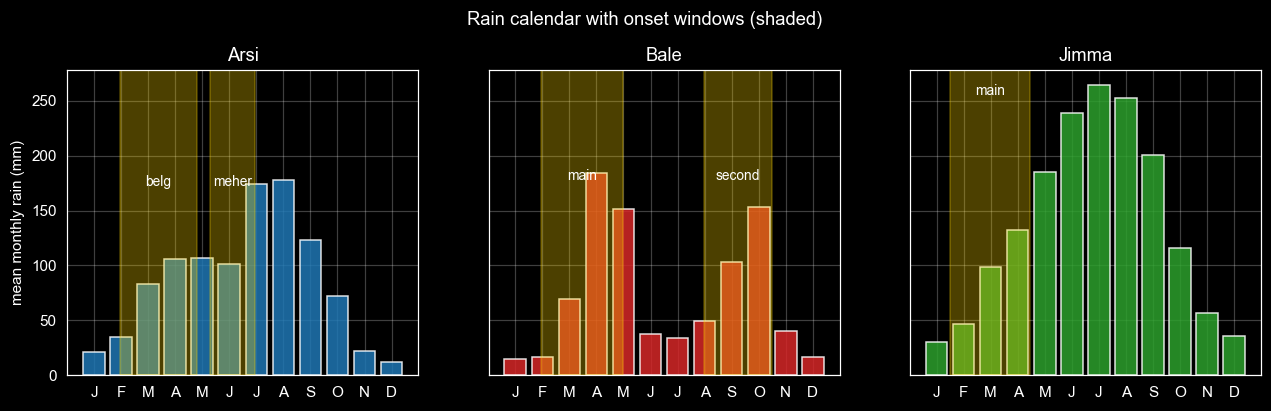

In [17]:
monthly = (full.groupby(["region", "year", "month"])["rain_mm"].sum()
               .groupby(["region", "month"]).mean().unstack(0))

def month_pos(md_str):                       # "MM-DD" -> position on a 0..12 axis
    m, d = map(int, md_str.split("-"))
    return (m - 1) + (d - 1) / 30

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, region in zip(axes, REGION_NAMES):
    ax.bar(np.arange(12) + 0.5, monthly[region].values, width=0.8, color=COLORS[region], alpha=0.85)
    for wname, a, b in cfg.ONSET_WINDOWS[region]:
        ax.axvspan(month_pos(a), month_pos(b), color="gold", alpha=0.3)
        ax.text((month_pos(a) + month_pos(b)) / 2, ax.get_ylim()[1] * 0.92, wname, ha="center", fontsize=9)
    ax.set_xticks(np.arange(12) + 0.5, MONTHS)
    ax.set_title(region)
axes[0].set_ylabel("mean monthly rain (mm)")
fig.suptitle("Rain calendar with onset windows (shaded)", y=1.03)
savefig("eda_rain_calendar")
plt.show()

## 3. Year-to-year variability
The wetter the region, the less the year-to-year swing in relative terms. Large swings are why a single "normal" rain date does not work.

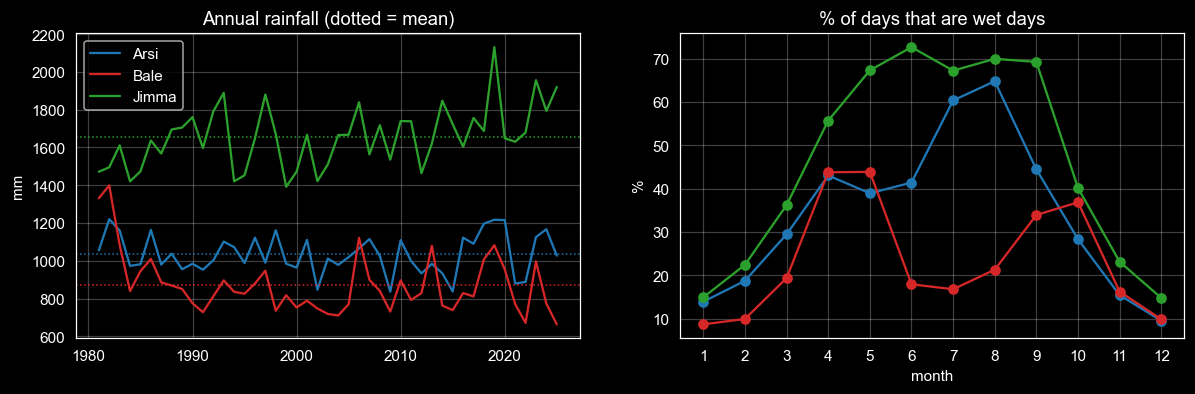

coefficient of variation of annual rain (std / mean):


,CV
region,
Arsi,0.10
Bale,0.18
Jimma,0.10


In [18]:
annual = yearly[yearly["complete"]].pivot(index="year", columns="region", values="rain_total_mm")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for region in annual.columns:
    axes[0].plot(annual.index, annual[region], color=COLORS[region], label=region)
    axes[0].axhline(annual[region].mean(), color=COLORS[region], ls=":", lw=1)
axes[0].set(title="Annual rainfall (dotted = mean)", ylabel="mm")
axes[0].legend()

wet_freq = (full.groupby(["region", "month"])["wet_day"].mean().unstack(0) * 100)
for region in wet_freq.columns:
    axes[1].plot(range(1, 13), wet_freq[region], color=COLORS[region], marker="o", label=region)
axes[1].set(title="% of days that are wet days", xlabel="month", ylabel="%")
axes[1].set_xticks(range(1, 13))
savefig("eda_annual_and_wet_days")
plt.show()

print("coefficient of variation of annual rain (std / mean):")
display((annual.std() / annual.mean()).round(2).to_frame("CV"))

## 4. How are daily rain amounts distributed?
Most days are dry or light; a few heavy days carry most of the rain. That is why we look at **intensity** (max daily rain, mm per wet day) as well as totals.

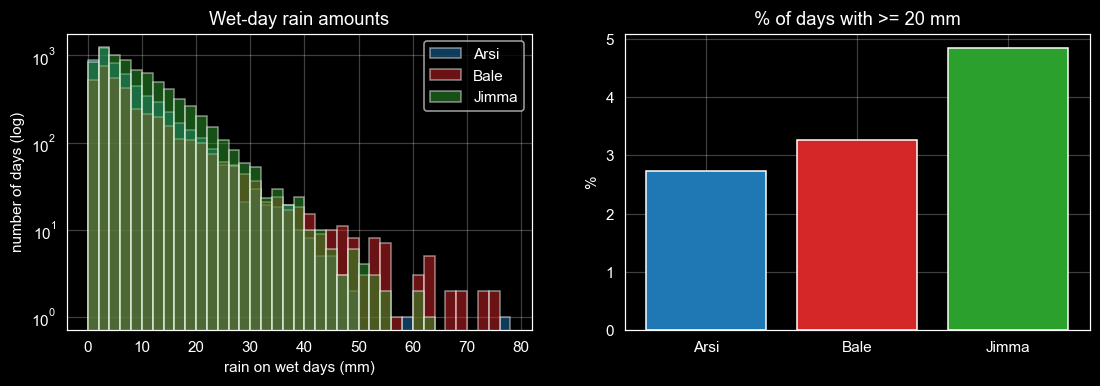

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for region in REGION_NAMES:
    r = full.loc[(full["region"] == region) & (full["rain_mm"] >= cfg.TRIGGER_WET_DAY_MM), "rain_mm"]
    axes[0].hist(r, bins=np.arange(0, 80, 2), alpha=0.5, color=COLORS[region], label=region)
axes[0].set(yscale="log", xlabel="rain on wet days (mm)", ylabel="number of days (log)", title="Wet-day rain amounts")
axes[0].legend()

share = full.assign(heavy=full["rain_mm"] >= 20).groupby("region")["heavy"].mean() * 100
axes[1].bar(share.index, share.values, color=[COLORS[r] for r in share.index])
axes[1].set(title="% of days with >= 20 mm", ylabel="%")
savefig("eda_rain_distribution")
plt.show()

## 5. Atmospheric demand - how fast does water leave?
VPD, ET0 and maximum temperature by month. The dry months before the main rains are when evaporative demand peaks, so a dry spell right after an early planting is most dangerous.

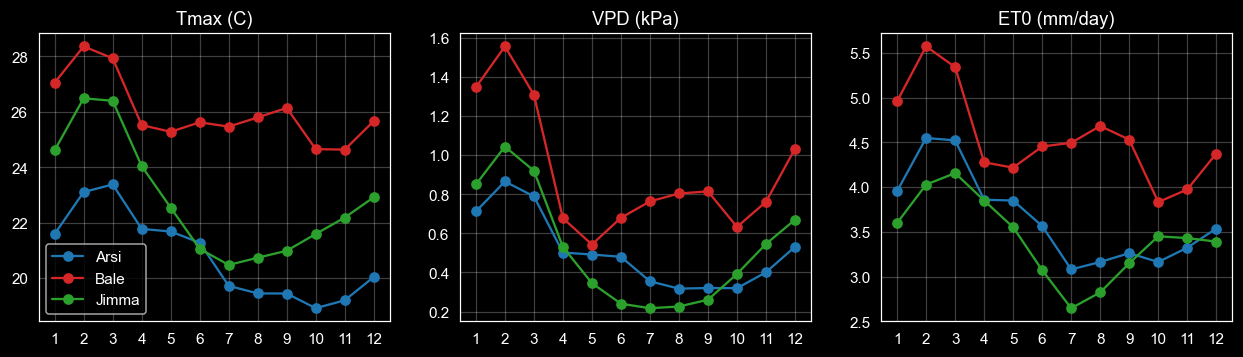

In [20]:
clim = full.groupby(["region", "month"])[["tmax_c", "vpd_kpa", "et0_mm"]].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, var, title in zip(axes, ["tmax_c", "vpd_kpa", "et0_mm"],
                          ["Tmax (C)", "VPD (kPa)", "ET0 (mm/day)"]):
    for region in REGION_NAMES:
        ax.plot(range(1, 13), clim.loc[region, var], color=COLORS[region], marker="o", label=region)
    ax.set_title(title)
    ax.set_xticks(range(1, 13))
axes[0].legend()
savefig("eda_atmospheric_demand")
plt.show()

## 6. Soil moisture and how much we can trust ERA5-Land
ERA5-Land is a reanalysis (a model), so we compare it with **SMAP**, an independent satellite estimate, for 2015 onward.
High correlation means ERA5-Land's wetting and drying pattern is realistic, which justifies using it for the 45-year history.

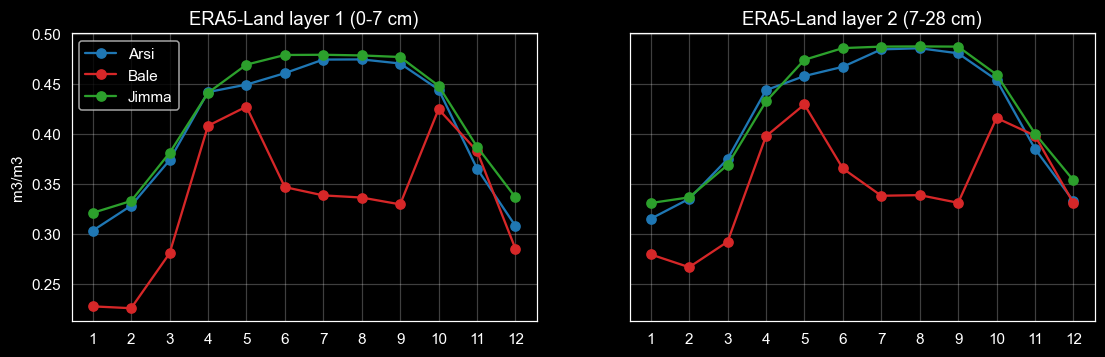

In [21]:
sm_clim = full.groupby(["region", "month"])[["sm_l1", "sm_l2"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, layer, title in zip(axes, ["sm_l1", "sm_l2"], ["ERA5-Land layer 1 (0-7 cm)", "ERA5-Land layer 2 (7-28 cm)"]):
    for region in REGION_NAMES:
        ax.plot(range(1, 13), sm_clim.loc[region, layer], color=COLORS[region], marker="o", label=region)
    ax.set_title(title)
    ax.set_xticks(range(1, 13))
axes[0].set_ylabel("m3/m3")
axes[0].legend()
plt.show()

,r ERA5 layer1 vs SMAP L4 surface,r ERA5 layer1 vs SMAP L3 (observed),days compared (L4)
region,,,
Arsi,0.69,0.86,4202
Bale,0.83,0.81,4202
Jimma,0.68,0.84,4202


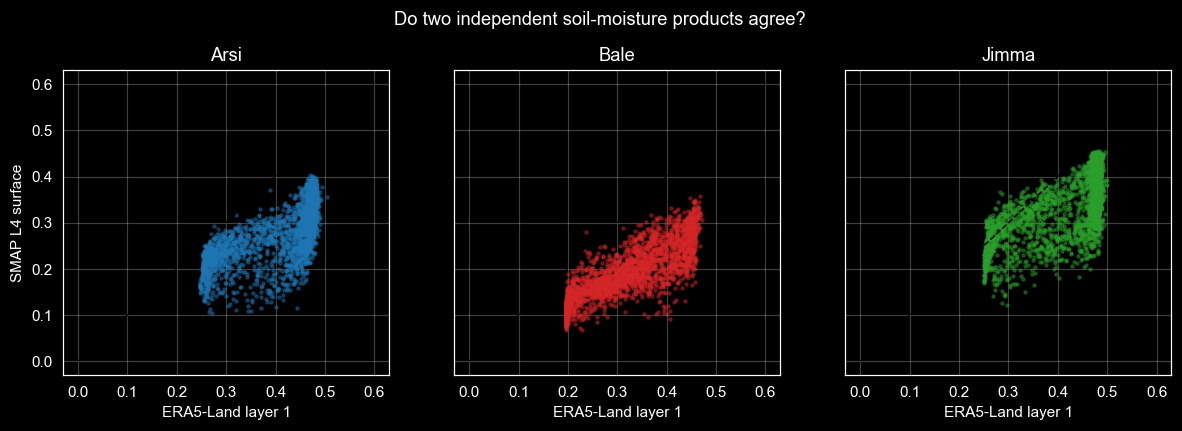

In [22]:
smap = daily.dropna(subset=["smap_l4_surface", "sm_l1"])
rows = []
for region, g in smap.groupby("region"):
    g3 = g.dropna(subset=["smap_l3_sm"])
    rows.append({"region": region,
                 "r  ERA5 layer1 vs SMAP L4 surface": round(g["sm_l1"].corr(g["smap_l4_surface"]), 2),
                 "r  ERA5 layer1 vs SMAP L3 (observed)": round(g3["sm_l1"].corr(g3["smap_l3_sm"]), 2),
                 "days compared (L4)": len(g)})
display(pd.DataFrame(rows).set_index("region"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, (region, g) in zip(axes, smap.groupby("region")):
    s = g.sample(min(2500, len(g)), random_state=0)
    ax.scatter(s["sm_l1"], s["smap_l4_surface"], s=4, alpha=0.4, color=COLORS[region])
    ax.plot([0, 0.6], [0, 0.6], "k--", lw=1)
    ax.set(title=region, xlabel="ERA5-Land layer 1")
axes[0].set_ylabel("SMAP L4 surface")
fig.suptitle("Do two independent soil-moisture products agree?", y=1.03)
savefig("eda_era5_vs_smap")
plt.show()

## 7. Do rainfall sources agree? (CHIRPS vs IMERG vs ERA5)
We use CHIRPS for labels. If IMERG and ERA5-Land give similar monthly totals, the rainfall signal is robust and not an artefact of one product.
A big constant ratio between products points to a unit or conversion mistake.

,r CHIRPS-IMERG (monthly),r CHIRPS-ERA5 (monthly),IMERG / CHIRPS total,ERA5 / CHIRPS total
region,,,,
Arsi,0.92,0.84,0.87,3.61
Bale,0.90,0.86,1.00,1.21
Jimma,0.93,0.90,0.97,1.20


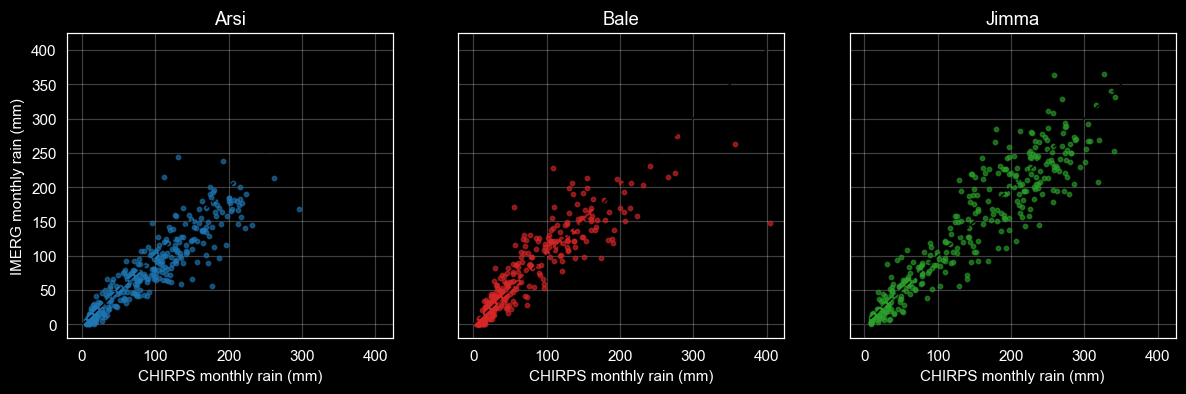

In [23]:
cmp_ = (daily[["date", "region", "rain_mm"]]
        .merge(imerg, on=["date", "region"])
        .merge(era5w[["date", "region", "era5_rain_mm"]], on=["date", "region"])
        .dropna())
monthly_cmp = (cmp_.set_index("date").groupby("region")[["rain_mm", "imerg_mm", "era5_rain_mm"]]
               .resample("MS").sum().reset_index())

rows = []
for region, g in monthly_cmp.groupby("region"):
    rows.append({"region": region,
                 "r CHIRPS-IMERG (monthly)": round(g["rain_mm"].corr(g["imerg_mm"]), 2),
                 "r CHIRPS-ERA5 (monthly)": round(g["rain_mm"].corr(g["era5_rain_mm"]), 2),
                 "IMERG / CHIRPS total": round(g["imerg_mm"].sum() / g["rain_mm"].sum(), 2),
                 "ERA5 / CHIRPS total": round(g["era5_rain_mm"].sum() / g["rain_mm"].sum(), 2)})
display(pd.DataFrame(rows).set_index("region"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
for ax, (region, g) in zip(axes, monthly_cmp.groupby("region")):
    ax.scatter(g["rain_mm"], g["imerg_mm"], s=8, alpha=0.6, color=COLORS[region])
    lim = max(g["rain_mm"].max(), g["imerg_mm"].max())
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    ax.set(title=region, xlabel="CHIRPS monthly rain (mm)")
axes[0].set_ylabel("IMERG monthly rain (mm)")
savefig("eda_chirps_vs_imerg")
plt.show()

## 8. Onset events and labels
From here on we need the output of `create_labels.py`. An **onset event** is the first day that meets the trigger rule (>= 20 mm in 3 days with >= 2 wet days) inside a region's onset window.
It is a **false start** if a run of dry days (rule in `label_config.py`) follows within 30 days.

In [24]:
events = load_table("onset_events", parse_dates=("trigger_date",))
ok = events[events["label_complete"]].copy()
ok["doy"] = ok["trigger_date"].dt.dayofyear

print("labelled events:", len(ok), "| false starts:", int(ok["false_start"].sum()),
      f"({ok['false_start'].mean():.1%})")
display(ok.groupby(["region", "window"]).agg(events=("false_start", "size"),
                                             false_starts=("false_start", "sum"),
                                             rate=("false_start", "mean")).round(2))

labelled events: 229 | false starts: 114 (49.8%)


events  false_starts  rate
region window                            
Arsi   belg        46          29.0  0.63
       meher       46          13.0  0.28
Bale   main        46          26.0  0.57
       second      45          22.0  0.49
Jimma  main        46          24.0  0.52

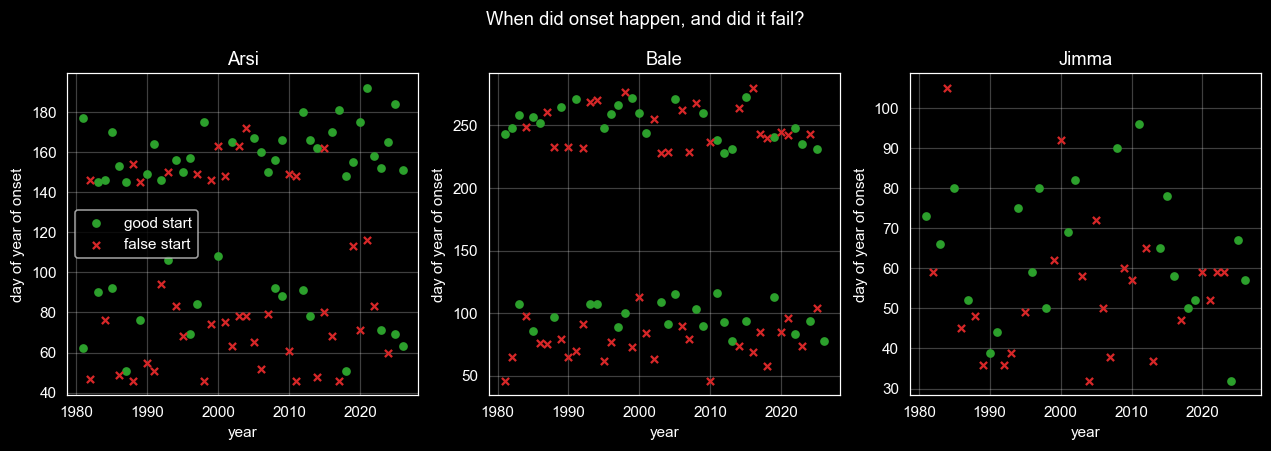

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=False)
for ax, region in zip(axes, REGION_NAMES):
    g = ok[ok["region"] == region]
    good, bad = g[g["false_start"] == 0], g[g["false_start"] == 1]
    ax.scatter(good["year"], good["doy"], color="#2ca02c", s=22, label="good start")
    ax.scatter(bad["year"], bad["doy"], color="#d62728", s=22, marker="x", label="false start")
    ax.set(title=region, xlabel="year", ylabel="day of year of onset")
axes[0].legend()
fig.suptitle("When did onset happen, and did it fail?", y=1.03)
savefig("eda_onset_dates")
plt.show()

### One false start and one good start, side by side
Rain bars with the dry days marked, soil moisture and VPD. This is the chart that tells the whole story in one picture:
after the trigger rain, soil moisture rises, then **drops quickly when no rain follows and VPD is high**.

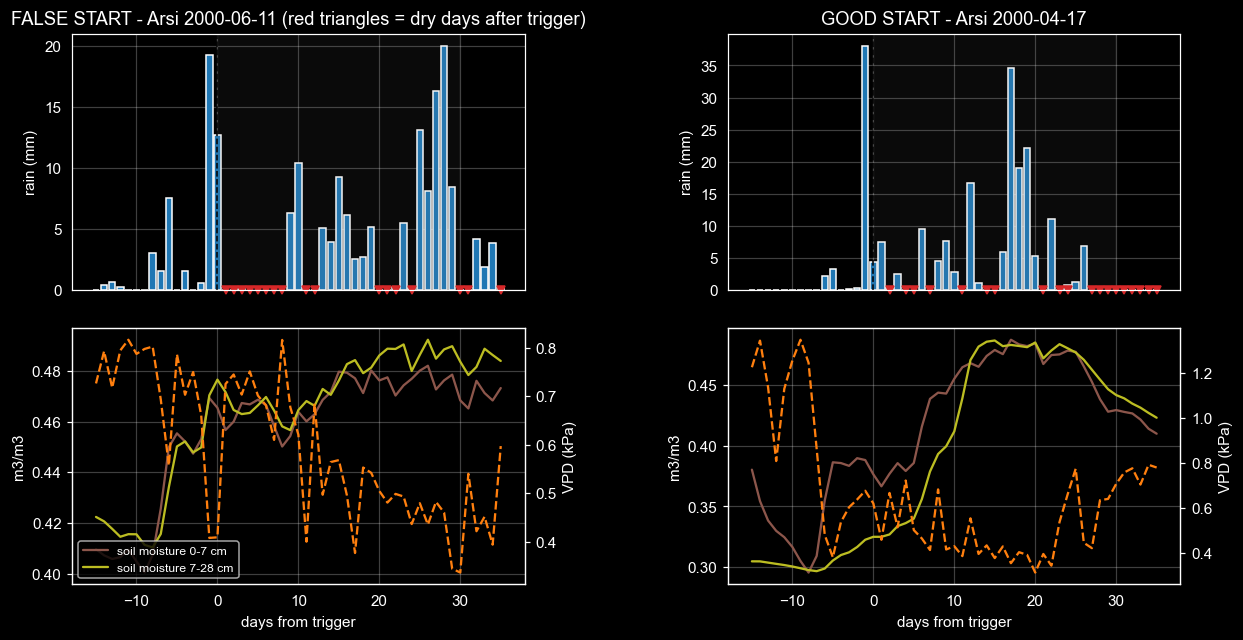

In [26]:
cand = ok[ok["year"] >= 2000]
fs = cand[cand["false_start"] == 1].iloc[0]
gs_pool = cand[(cand["false_start"] == 0) & (cand["region"] == fs["region"])]
gs = (gs_pool if len(gs_pool) else cand[cand["false_start"] == 0]).iloc[0]

def event_panel(ev, ax_rain, ax_soil, title):
    t = ev["trigger_date"]
    d = daily[(daily["region"] == ev["region"]) &
              (daily["date"] >= t - pd.Timedelta(days=15)) & (daily["date"] <= t + pd.Timedelta(days=35))]
    x = (d["date"] - t).dt.days
    dry = d["rain_mm"] < cfg.DRY_DAY_MM
    ax_rain.bar(x, d["rain_mm"], color="#1f77b4")
    mark = dry & (x > 0)
    ax_rain.plot(x[mark], np.zeros(int(mark.sum())), "v", color="#d62728", markersize=5, clip_on=False)
    ax_rain.axvline(0, color="k", ls="--", lw=1)
    ax_rain.axvspan(0, cfg.FOLLOW_DAYS, color="grey", alpha=0.08)
    ax_rain.set(title=title, ylabel="rain (mm)")
    ax_soil.plot(x, d["sm_l1"], color="#8c564b", label="soil moisture 0-7 cm")
    ax_soil.plot(x, d["sm_l2"], color="#bcbd22", label="soil moisture 7-28 cm")
    ax_soil.set(xlabel="days from trigger", ylabel="m3/m3")
    ax_v = ax_soil.twinx()
    ax_v.plot(x, d["vpd_kpa"], color="#ff7f0e", ls="--", label="VPD")
    ax_v.set_ylabel("VPD (kPa)")
    ax_v.grid(False)

fig, axes = plt.subplots(2, 2, figsize=(13, 6.5), sharex=True)
fig.subplots_adjust(wspace=0.45, hspace=0.15)
event_panel(fs, axes[0, 0], axes[1, 0],
            f"FALSE START - {fs['region']} {fs['trigger_date'].date()} (red triangles = dry days after trigger)")
event_panel(gs, axes[0, 1], axes[1, 1],
            f"GOOD START - {gs['region']} {gs['trigger_date'].date()}")
axes[1, 0].legend(loc="lower left", fontsize=8)
savefig("eda_false_vs_good_start_example")
plt.show()

## 9. How often do false starts happen - and how much does the definition matter?
The false-start rate depends on what you call a "dry spell". This table is the evidence for your threshold choice.
**Choose the rule for agronomic reasons and write down why; do not choose it to get a convenient class balance.**

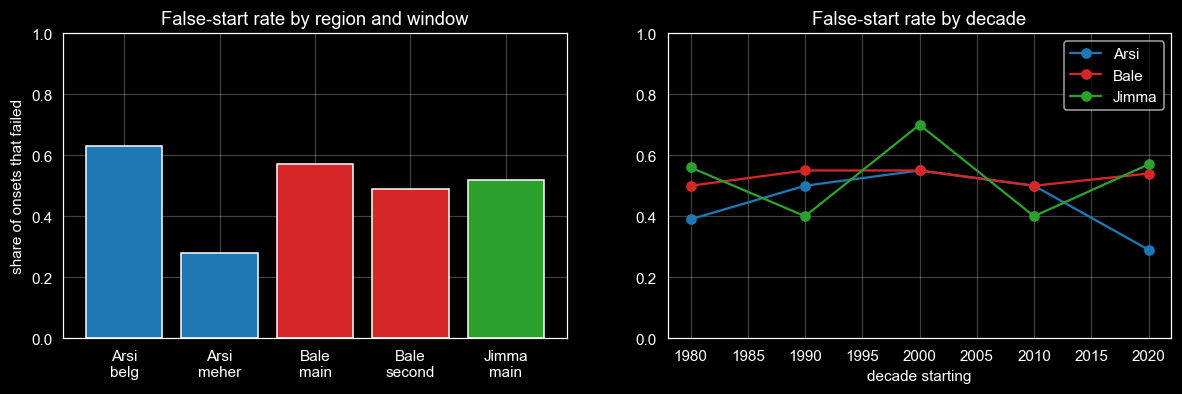

In [27]:
rate_rw = ok.groupby(["region", "window"])["false_start"].mean().round(2)
ok["period"] = (ok["year"] // 10) * 10
rate_decade = ok.groupby(["period", "region"])["false_start"].mean().unstack().round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
labels = [f"{r}\n{w}" for r, w in rate_rw.index]
colors = [COLORS[r] for r, _ in rate_rw.index]
axes[0].bar(labels, rate_rw.values, color=colors)
axes[0].set(title="False-start rate by region and window", ylabel="share of onsets that failed", ylim=(0, 1))

for region in rate_decade.columns:
    axes[1].plot(rate_decade.index, rate_decade[region], marker="o", color=COLORS[region], label=region)
axes[1].set(title="False-start rate by decade", ylim=(0, 1), xlabel="decade starting")
axes[1].legend()
savefig("eda_false_start_rates")
plt.show()

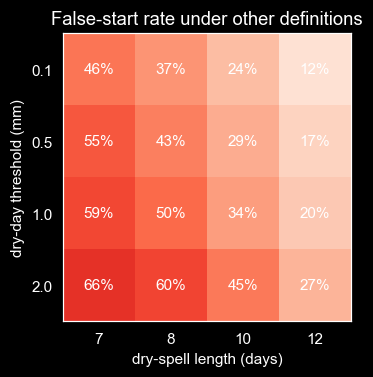

Current rule: dry day < 1.0 mm, spell >= 8 days, within 30 days


In [28]:
sens = load_table("label_sensitivity", parse_dates=())
pv = sens.pivot(index="dry_day_mm", columns="dry_spell_days", values="false_start_rate")

fig, ax = plt.subplots(figsize=(6, 3.4))
im = ax.imshow(pv.values, cmap="Reds", vmin=0, vmax=1)
ax.set_xticks(range(len(pv.columns)), pv.columns)
ax.set_yticks(range(len(pv.index)), pv.index)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        ax.text(j, i, f"{pv.values[i, j]:.0%}", ha="center", va="center")
ax.set(xlabel="dry-spell length (days)", ylabel="dry-day threshold (mm)",
       title="False-start rate under other definitions")
ax.grid(False)
savefig("eda_label_sensitivity")
plt.show()
print(f"Current rule: dry day < {cfg.DRY_DAY_MM} mm, spell >= {cfg.DRY_SPELL_DAYS} days, within {cfg.FOLLOW_DAYS} days")

## 10. What separates a false start from a good start? (features)
For each feature, compare the two groups at the trigger day. Features whose boxes barely overlap carry the most signal.
This is **descriptive**, not proof: correlated features and only ~200 events mean the model results will be noisy.

       rows  false_starts  rate
split                          
test     54            25  0.46
train   175            89  0.51



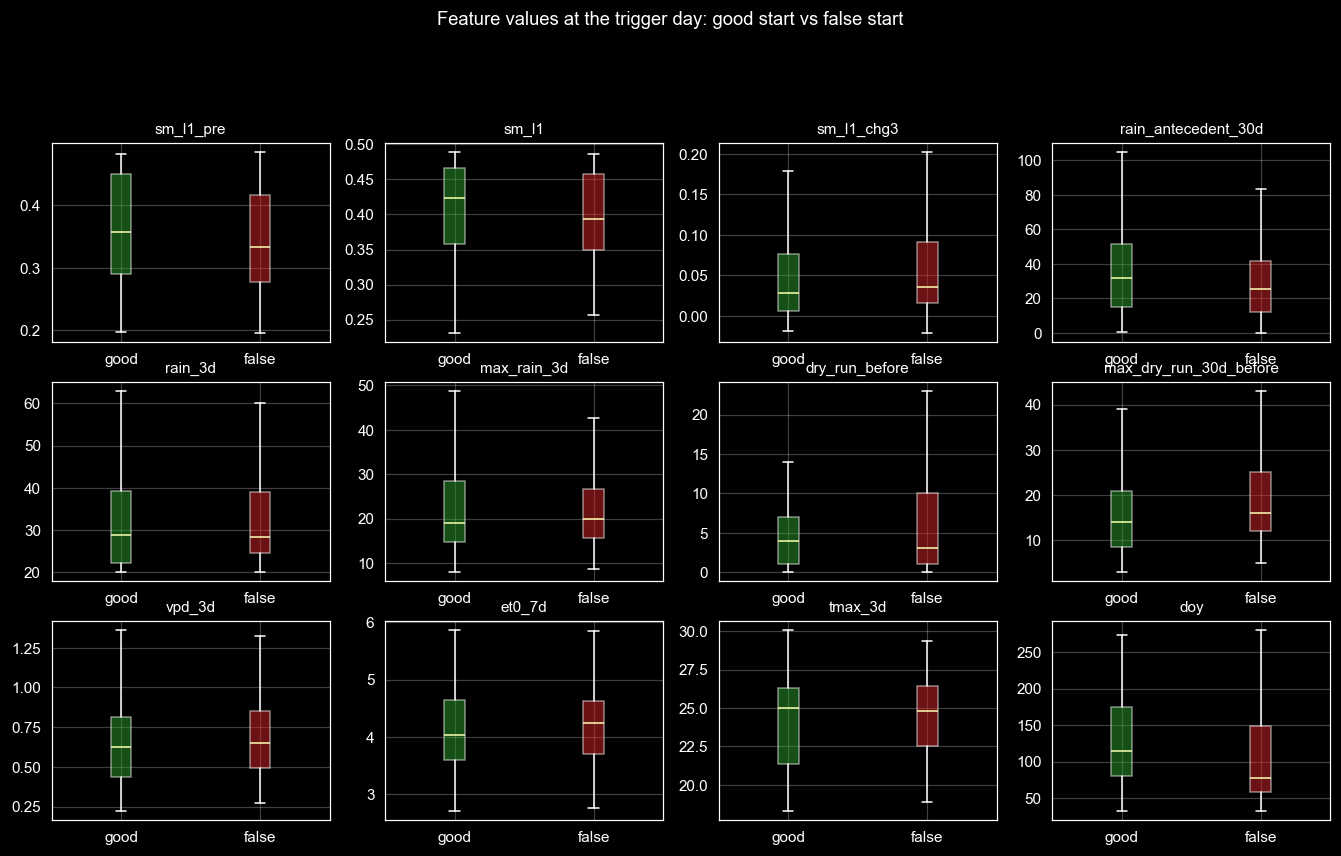

In [29]:
train = load_table("training_dataset", parse_dates=("trigger_date",))
import json
info = json.loads((PROC_DIR / "feature_list.json").read_text(encoding="utf-8"))
num = info["numeric_features"]

print(train.groupby("split")["false_start"].agg(rows="size", false_starts="sum", rate="mean").round(2))
print()
show = ["sm_l1_pre", "sm_l1", "sm_l1_chg3", "rain_antecedent_30d", "rain_3d", "max_rain_3d",
        "dry_run_before", "max_dry_run_30d_before", "vpd_3d", "et0_7d", "tmax_3d", "doy"]
show = [c for c in show if c in train.columns]

fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, col in zip(axes.ravel(), show):
    data = [train.loc[train["false_start"] == 0, col].dropna(), train.loc[train["false_start"] == 1, col].dropna()]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    ax.set_xticks([1, 2], ["good", "false"])
    for patch, c in zip(bp["boxes"], ["#2ca02c", "#d62728"]):
        patch.set_facecolor(c)
        patch.set_alpha(0.5)
    ax.set_title(col, fontsize=10)
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.suptitle("Feature values at the trigger day: good start vs false start", y=1.03)
savefig("eda_features_by_label")
plt.show()

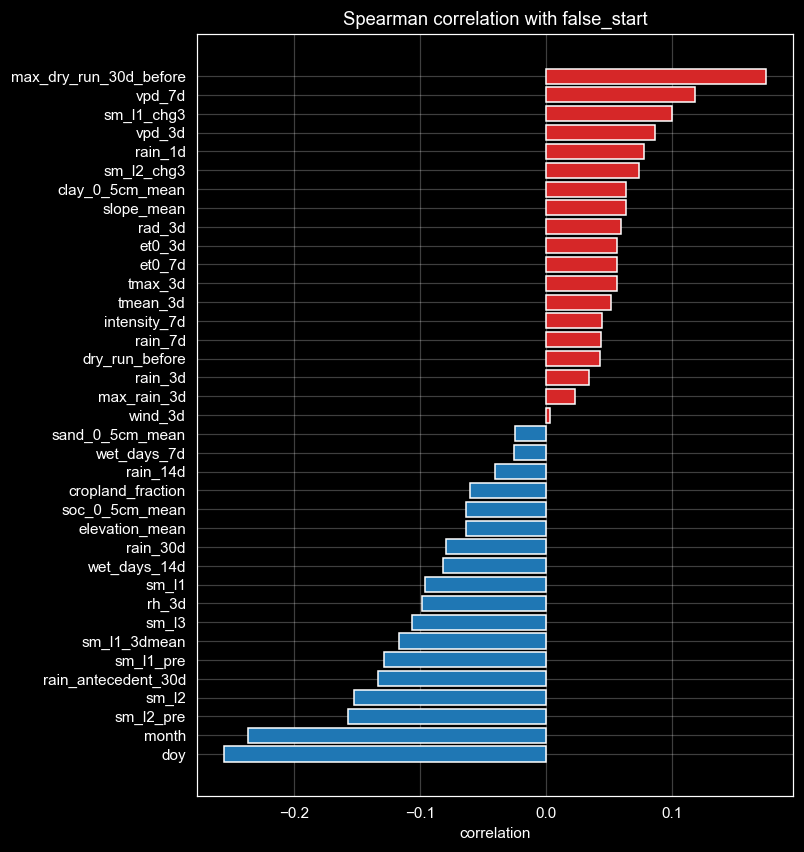

In [30]:
corr_y = train[num].corrwith(train["false_start"], method="spearman").dropna().sort_values()
fig, ax = plt.subplots(figsize=(7, 9))
ax.barh(corr_y.index, corr_y.values, color=np.where(corr_y.values > 0, "#d62728", "#1f77b4"))
ax.set(title="Spearman correlation with false_start", xlabel="correlation")
savefig("eda_feature_correlation_with_target")
plt.show()

### Are features redundant?
Many of our features are windows of the same variable (rain over 3, 7, 14, 30 days). Highly correlated features make coefficients unstable and importance scores misleading, so check this before modelling.

,feature_a,feature_b,rho
1218,slope_mean,clay_0_5cm_mean,1.000000
1294,clay_0_5cm_mean,soc_0_5cm_mean,-1.000000
1220,slope_mean,soc_0_5cm_mean,-1.000000
1183,elevation_mean,soc_0_5cm_mean,1.000000
1181,elevation_mean,clay_0_5cm_mean,-1.000000
1179,elevation_mean,slope_mean,-1.000000
1103,doy,month,0.981059
457,tmean_3d,tmax_3d,0.953470
535,rh_3d,vpd_3d,-0.940503
801,sm_l1,sm_l1_3dmean,0.937821


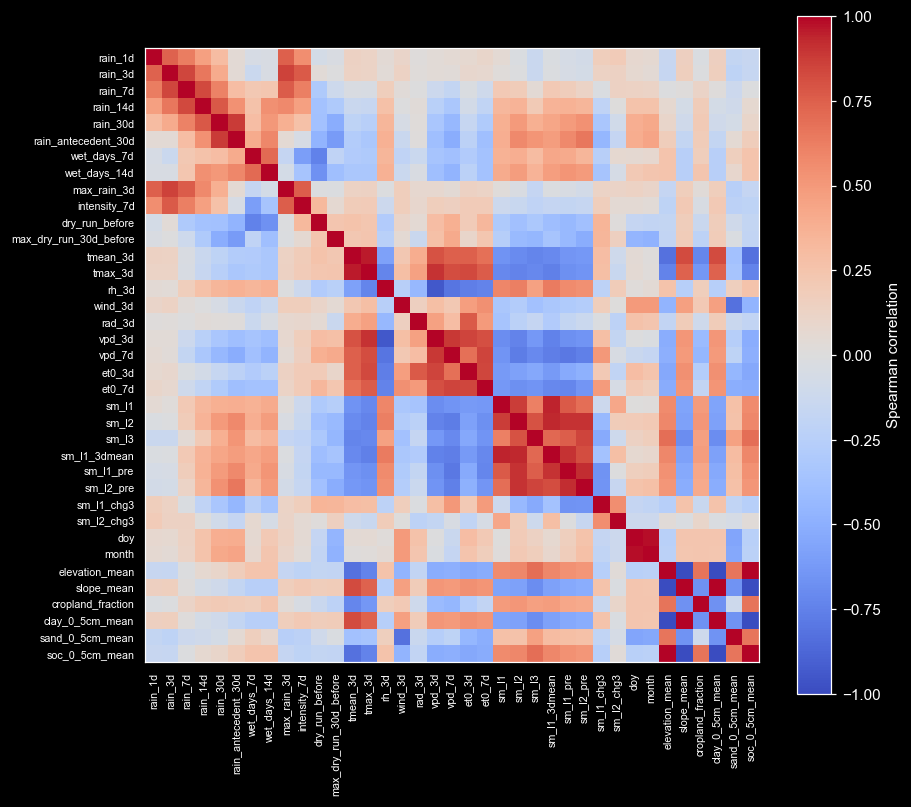

In [31]:
cm = train[num].corr(method="spearman")
pairs = (cm.where(np.triu(np.ones(cm.shape), k=1).astype(bool)).stack().rename("rho").reset_index()
           .rename(columns={"level_0": "feature_a", "level_1": "feature_b"}))
display(pairs[pairs["rho"].abs() > 0.9].sort_values("rho", key=abs, ascending=False).head(15))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=90, fontsize=7)
ax.set_yticks(range(len(num)), num, fontsize=7)
ax.grid(False)
plt.colorbar(im, label="Spearman correlation")
savefig("eda_feature_correlation_matrix")
plt.show()

## 11. Does the vegetation confirm the labels? (validation, MODIS NDVI)
NDVI is **not** a model input. If our labels are meaningful, NDVI after a false start should rise less (or fall back) compared with a good start.
For every event, NDVI in the 16-day windows after the trigger is compared with the composite just before it.

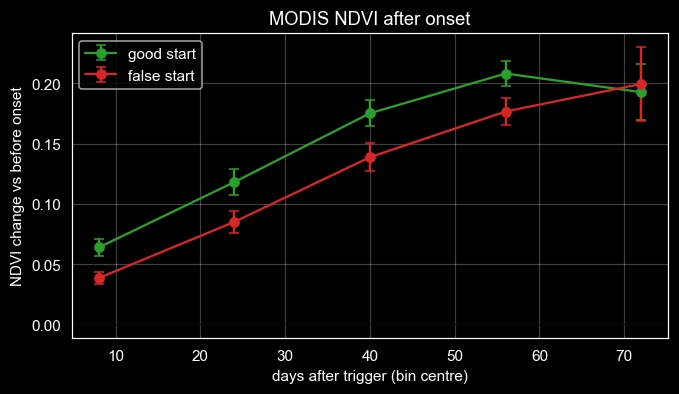

In [32]:
modis = veg[veg["source"] == "MODIS"][["date", "region", "ndvi"]].dropna()
rows = []
for _, e in ok[ok["year"] >= 2001].iterrows():
    v = modis[(modis["region"] == e["region"]) &
              (modis["date"] >= e["trigger_date"] - pd.Timedelta(days=16)) &
              (modis["date"] <= e["trigger_date"] + pd.Timedelta(days=64))].copy()
    v["offset"] = (v["date"] - e["trigger_date"]).dt.days
    base = v.loc[v["offset"] <= 0, "ndvi"]
    if base.empty:
        continue
    base_val = base.iloc[-1]
    for off, n in zip(v["offset"], v["ndvi"]):
        if off > 0:
            rows.append({"false_start": e["false_start"], "bin": (off // 16) * 16 + 8, "ndvi_change": n - base_val})
ndvi_after = pd.DataFrame(rows)

if ndvi_after.empty:
    print("No MODIS observations found around the events.")
else:
    agg = ndvi_after.groupby(["false_start", "bin"])["ndvi_change"].agg(["mean", "sem"]).reset_index()
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for flag, label, c in [(0, "good start", "#2ca02c"), (1, "false start", "#d62728")]:
        a = agg[agg["false_start"] == flag]
        ax.errorbar(a["bin"], a["mean"], yerr=a["sem"], marker="o", color=c, label=label, capsize=3)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="days after trigger (bin centre)", ylabel="NDVI change vs before onset",
           title="MODIS NDVI after onset")
    ax.legend()
    savefig("eda_ndvi_after_onset")
    plt.show()

## 12. What to write down
Fill these in with your own findings (they become your presentation notes):

1. **Rain calendar:** which seasons does each region have, and are the onset windows justified?
2. **Label rule:** how does the false-start rate change with the dry-spell definition, and which rule did you choose and why?
3. **Mechanism:** in the example chart, what happens to soil moisture and VPD after a false start?
4. **Data agreement:** how well do ERA5-Land and SMAP, and CHIRPS and IMERG, agree?
5. **Features:** which features separate the two groups, and which are redundant?
6. **Vegetation check:** does NDVI support the labels, and how strongly?
7. **Limits:** number of events, only 3 regions, labels from rainfall rules and not from observed crop failure.